<a href="https://colab.research.google.com/github/sucharitacs24/bis-lab/blob/main/Particle%20Swarm%20Optimisation%20-Particle%20Swarm%20Optimization%3A%20A%20Comprehensive%20Survey%20(2022)" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


PARTICLE SWARM OPTIMIZATION RESULTS
-----------------------------------
Best Solution: [1.11282856e-11 4.20135366e-12]
Best Fitness: 1.414901124861692e-22


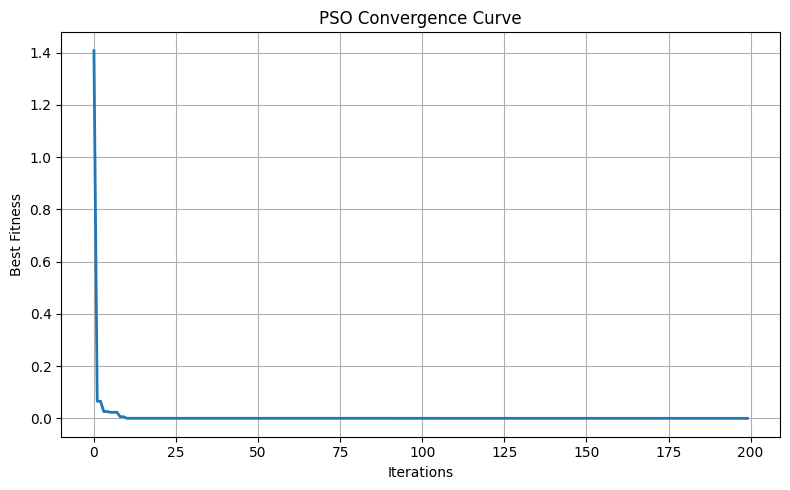

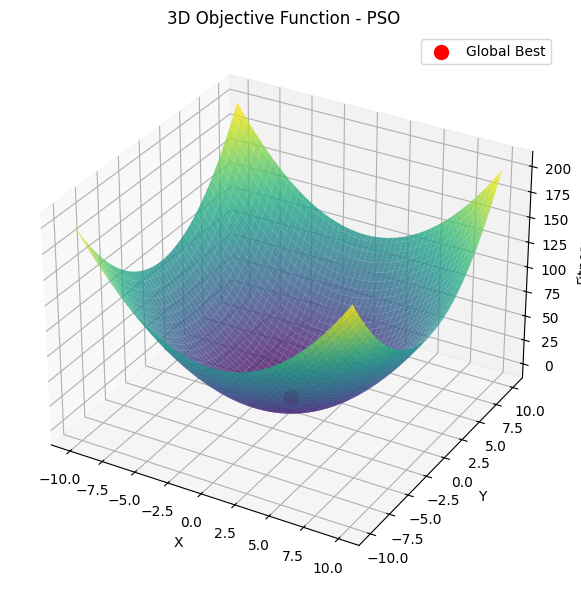

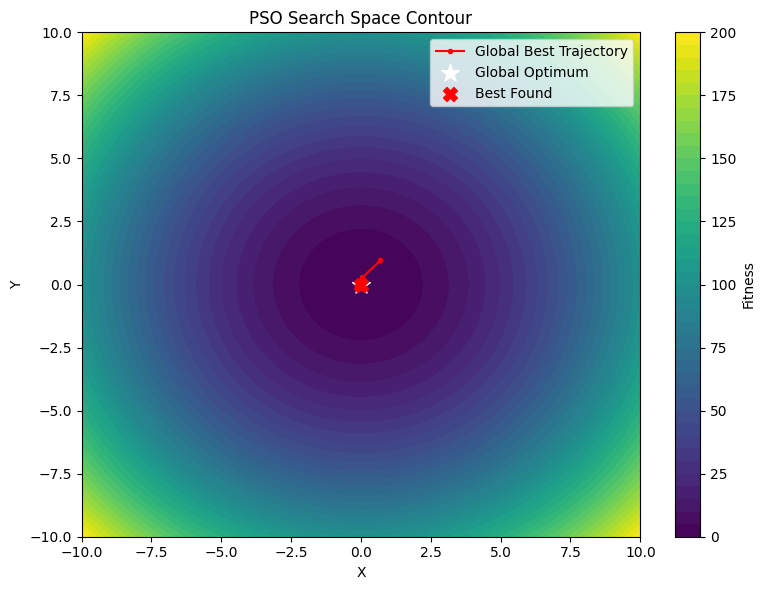

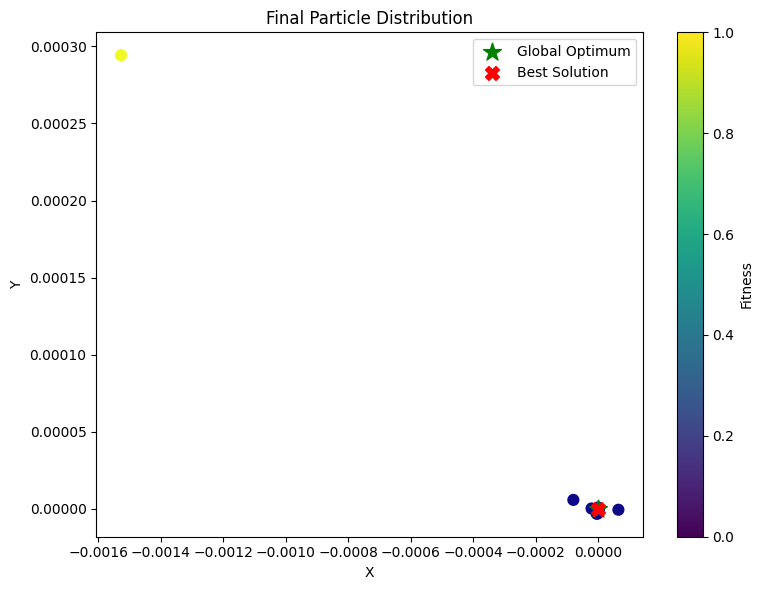

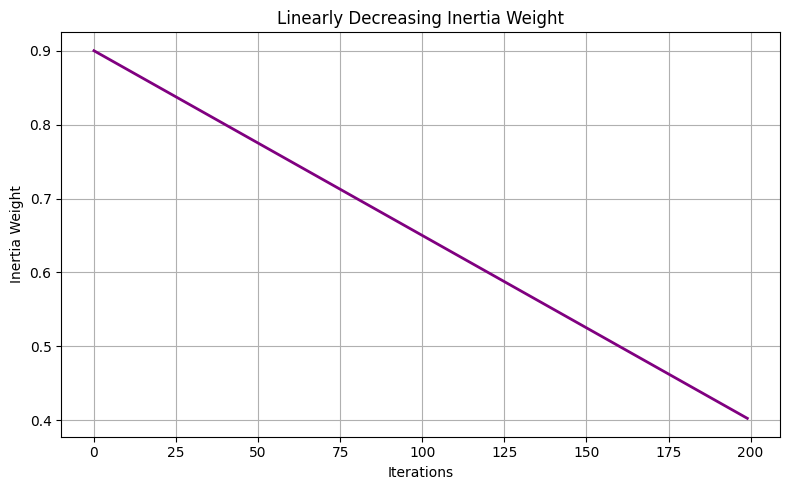

In [1]:

import numpy as np
import matplotlib.pyplot as plt

# ---------------- PARAMETERS ----------------

N = 50
DIM = 2
ITERATIONS = 200

W_MAX = 0.9
W_MIN = 0.4

C1 = 2.0
C2 = 2.0

LOWER = -10
UPPER = 10

rng = np.random.default_rng(42)

# ---------------- OBJECTIVE FUNCTION ----------------

def objective(x):
    return np.sum(x ** 2)

# ---------------- INITIALIZATION ----------------

positions = rng.uniform(
    LOWER, UPPER, (N, DIM)
)

velocities = rng.uniform(
    -1, 1, (N, DIM)
)

personal_best = positions.copy()

personal_fitness = np.array([
    objective(x) for x in positions
])

best_index = np.argmin(personal_fitness)

global_best = personal_best[best_index].copy()
global_fitness = personal_fitness[best_index]

history = []
best_path = []
inertia_history = []

# ---------------- MAIN PSO LOOP ----------------

for iteration in range(ITERATIONS):

    # Linearly decreasing inertia weight
    w = W_MAX - (
        iteration / ITERATIONS
    ) * (W_MAX - W_MIN)

    inertia_history.append(w)

    for i in range(N):

        r1 = rng.random(DIM)
        r2 = rng.random(DIM)

        # Velocity update
        velocities[i] = (
            w * velocities[i]
            + C1 * r1 * (personal_best[i] - positions[i])
            + C2 * r2 * (global_best - positions[i])
        )

        # Limit velocity
        velocities[i] = np.clip(
            velocities[i], -2, 2
        )

        # Position update
        positions[i] += velocities[i]

        positions[i] = np.clip(
            positions[i], LOWER, UPPER
        )

        # Evaluate fitness
        current_fitness = objective(positions[i])

        # Update personal best
        if current_fitness < personal_fitness[i]:

            personal_best[i] = positions[i].copy()
            personal_fitness[i] = current_fitness

    # Update global best
    best_index = np.argmin(personal_fitness)

    if personal_fitness[best_index] < global_fitness:

        global_fitness = personal_fitness[best_index]
        global_best = personal_best[best_index].copy()

    history.append(global_fitness)
    best_path.append(global_best.copy())

# ---------------- RESULTS ----------------

print("\nPARTICLE SWARM OPTIMIZATION RESULTS")
print("-----------------------------------")
print("Best Solution:", global_best)
print("Best Fitness:", global_fitness)

# ---------------- OBJECTIVE SURFACE ----------------

x = np.linspace(LOWER, UPPER, 100)
y = np.linspace(LOWER, UPPER, 100)

X, Y = np.meshgrid(x, y)
Z = X**2 + Y**2

# ---------------- GRAPH 1: CONVERGENCE ----------------

plt.figure(figsize=(8, 5))

plt.plot(history, linewidth=2)

plt.xlabel("Iterations")
plt.ylabel("Best Fitness")
plt.title("PSO Convergence Curve")

plt.grid(True)
plt.tight_layout()
plt.show()

# ---------------- GRAPH 2: 3D SURFACE ----------------

fig = plt.figure(figsize=(9, 6))

ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(
    X, Y, Z,
    cmap="viridis",
    alpha=0.8
)

ax.scatter(
    global_best[0],
    global_best[1],
    global_fitness,
    color="red",
    s=100,
    label="Global Best"
)

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Fitness")

ax.set_title("3D Objective Function - PSO")
ax.legend()

plt.tight_layout()
plt.show()

# ---------------- GRAPH 3: CONTOUR ----------------

plt.figure(figsize=(8, 6))

plt.contourf(
    X, Y, Z,
    levels=40,
    cmap="viridis"
)

plt.colorbar(label="Fitness")

path = np.array(best_path)

plt.plot(
    path[:, 0],
    path[:, 1],
    "r.-",
    label="Global Best Trajectory"
)

plt.scatter(
    0, 0,
    color="white",
    marker="*",
    s=180,
    label="Global Optimum"
)

plt.scatter(
    global_best[0],
    global_best[1],
    color="red",
    marker="X",
    s=100,
    label="Best Found"
)

plt.xlabel("X")
plt.ylabel("Y")
plt.title("PSO Search Space Contour")

plt.legend()
plt.tight_layout()
plt.show()

# ---------------- GRAPH 4: FINAL PARTICLE DISTRIBUTION ----------------

plt.figure(figsize=(8, 6))

plt.scatter(
    positions[:, 0],
    positions[:, 1],
    c=[objective(p) for p in positions],
    cmap="plasma",
    s=60
)

plt.scatter(
    0, 0,
    color="green",
    marker="*",
    s=180,
    label="Global Optimum"
)

plt.scatter(
    global_best[0],
    global_best[1],
    color="red",
    marker="X",
    s=100,
    label="Best Solution"
)

plt.colorbar(label="Fitness")
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Final Particle Distribution")

plt.legend()
plt.tight_layout()
plt.show()

# ---------------- GRAPH 5: INERTIA WEIGHT ----------------

plt.figure(figsize=(8, 5))

plt.plot(
    inertia_history,
    color="purple",
    linewidth=2
)

plt.xlabel("Iterations")
plt.ylabel("Inertia Weight")
plt.title("Linearly Decreasing Inertia Weight")

plt.grid(True)
plt.tight_layout()
plt.show()
